In [1]:
from pprint import pprint
import os, sys
from pathlib import Path
from typing import Optional, Any, Callable, Union
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor, as_completed
from copy import deepcopy
from collections import defaultdict
from time import perf_counter

# import wandb
# from dask.distributed import Client, as_completed
import networkx as nx
import torch
import numpy as np
import numpy.linalg as npla
import pandas as pd
from sklearn.metrics import (
    f1_score, precision_score, recall_score, roc_auc_score,
    precision_recall_curve, auc, roc_curve
    )
from sklearn.model_selection import KFold
from tqdm import tqdm
import optuna
import omegaconf as oc
from omegaconf import OmegaConf
import matplotlib.pyplot as plt

from t_regs.multilinear_ops.tensor_products import multi_mode_product as mmp
from t_regs.solvers.manifold.minimax_problem import MinimaxProblem
from t_regs.solvers.manifold.rada import RADA_RGD
from t_regs.models.regression.tucker_nn_regressor import TuckerRegressor
from t_regs.models.regression.tucker_nn_bcd_v2 import TuckerRegressorBCD
from t_regs.synthetic_data.generate_lr_data import (
    generate_sparse_low_tucker_rank_tensor,
    generate_low_rank_data,
    generate_smooth_low_tucker_rank_tensor
    )
from t_regs.synthetic_data.regression import (
    generate_tensor_regression_predictors,
    generate_tensor_regression_response
    )

path = Path().cwd().parent.parent.parent
sys.path.append(str(path))

from experiments.synthetic.hp_study_utils import get_model, get_data
from experiments.synthetic.synthetic_study_utils import (
    register_resolvers,
    init_rada_rgd
    )

register_resolvers()

In [3]:
conf = OmegaConf.load('./../configs/eg1-ltr_sp_t_logreg.yaml')
conf.data.tensor_type = 'low_tucker_rank'
# conf.data.cardinalities = [4, 4, 4]
# conf.data.n_train = 10
# conf.data.n_samples = 8
# conf.data.n_val = 0
# conf.data.n_test = 1
conf.data.seed = 1
pprint(conf.data)
data = get_data(conf.data)

{'regression_type': 'logistic', 'tensor_type': 'low_tucker_rank', 'dims': [30, 30, 30], 'ranks': [3, 3, 3], 'cardinalities': [10, 10, 10], 'n_train': 6000, 'n_test': 1000, 'seed': 1, 'dtype': 'double', 'factor_graphs': [None, None, None]}


In [4]:
print(data['X'].shape)
# print(data['X_val'].shape)
print(data['X_test'].shape)

torch.Size([6000, 30, 30, 30])
torch.Size([1000, 30, 30, 30])


### Synthetic Low-Tucker Rank

{'regression_type': 'logistic', 'tensor_type': 'low_tucker_rank', 'dims': [30, 30, 30], 'ranks': [3, 3, 3], 'n_train': 1200, 'seed': 1, 'dtype': 'double', 'factor_graphs': [None, None, None]}


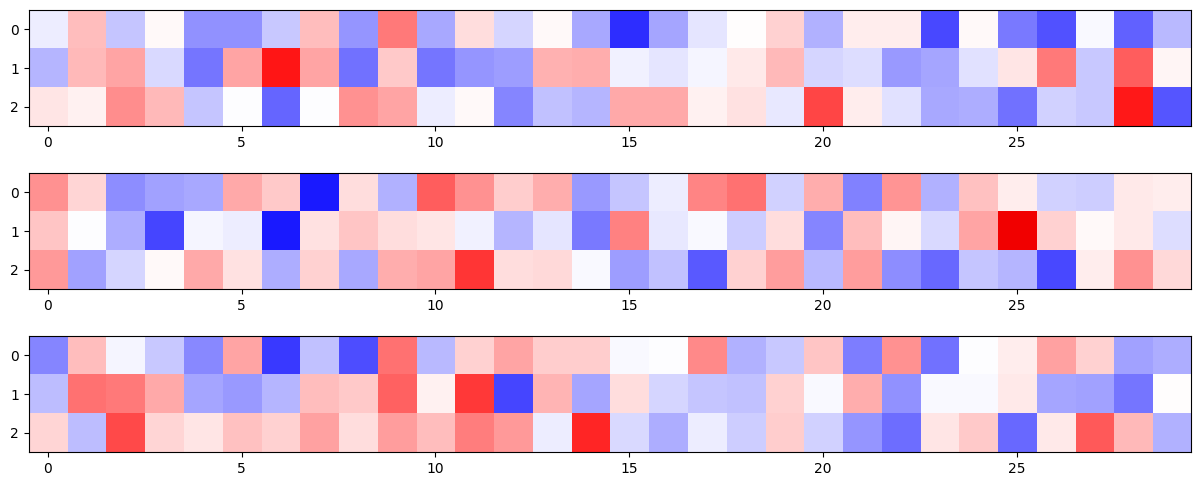

In [2]:
conf = OmegaConf.load('./../configs/study_0_a.yaml')
model_cfg = conf.model_cfg.copy()
conf.data.tensor_type = 'low_tucker_rank'
# conf.data.cardinalities = [4, 4, 4]
conf.data.n_train = 1200
conf.data.seed = 1
pprint(conf.data)
data = get_data(conf.data)

fig, axes = plt.subplots(
    len(data['Us_gt']), 1, figsize = (len(data['Us_gt'])*5, 6)
    )
if len(data['Us_gt']) == 1:
    axes = [axes]

for i, U in enumerate(data['Us_gt']):
    axes[i].imshow(U.T, vmin=-1, vmax=1, cmap='seismic')

**Verifying reproducibility:**

In [3]:
conf = OmegaConf.load('./../configs/study_0_a.yaml')
model_cfg = conf.model_cfg.copy()
conf.data.tensor_type = 'low_tucker_rank'
# conf.data.cardinalities = [4, 4, 4]
conf.data.n_train = 1200
conf.data.seed = 1
pprint(conf.data)
data = get_data(conf.data)
data1 = get_data(conf.data)
conf.data.seed = 2
data2 = get_data(conf.data)

print("B norm:", float(data['B_gt'].norm()))
print("B - B_1 norm: ", float(((data['B_gt'] - data1['B_gt'])**2).sum()))
print("B_1 - B_2 norm: ", float(((data['B_gt'] - data2['B_gt'])**2).sum()))

print("C - C_1 norm: ", float(((data['C_gt'] - data1['C_gt'])**2).sum()))
print("C_1 - C_2 norm: ", float(((data['C_gt'] - data2['C_gt'])**2).sum()))

print("X - X_1 norm: ", float(((data['X'] - data1['X'])**2).sum()))
print("X_1 - X_2 norm: ", float(((data['X'] - data2['X'])**2).sum()))

print("y - y_1 norm: ", float(((data['y'] - data1['y'])**2).sum()))
print("y_1 - y_2 norm: ", float(((data['y'] - data2['y'])**2).sum()))


{'regression_type': 'logistic', 'tensor_type': 'low_tucker_rank', 'dims': [30, 30, 30], 'ranks': [3, 3, 3], 'n_train': 1200, 'seed': 1, 'dtype': 'double', 'factor_graphs': [None, None, None]}
B norm: 4.517077904721047
B - B_1 norm:  0.0
B_1 - B_2 norm:  42.82488120078684
C - C_1 norm:  0.0
C_1 - C_2 norm:  28.126710259874507
X - X_1 norm:  0.0
X_1 - X_2 norm:  64788712.364294365
y - y_1 norm:  0.0
y_1 - y_2 norm:  576.0


### Sparse Factors $U_1,..., U_3$

{'regression_type': 'logistic', 'tensor_type': 'sparse_low_tucker_rank', 'dims': [30, 30, 30], 'ranks': [4, 4, 4], 'n_train': 1200, 'seed': 1, 'dtype': 'double', 'factor_graphs': [None, None, None], 'cardinalities': [8, 8, 8], 'expanded': True}


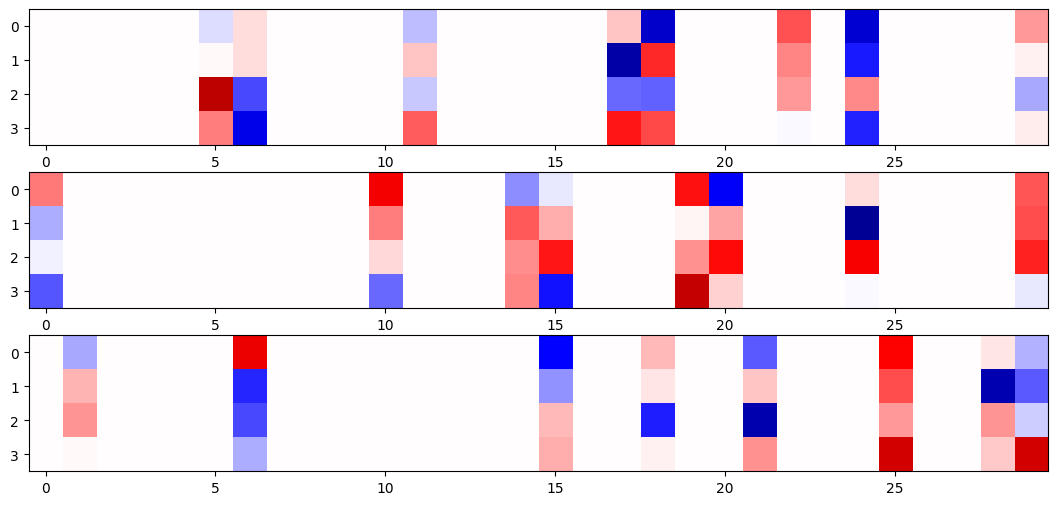

In [4]:
conf = OmegaConf.load('./../configs/study_0_a.yaml')
model_cfg = conf.model_cfg.copy()
conf.data.tensor_type = 'sparse_low_tucker_rank'
conf.data.cardinalities = [8, 8, 8]
conf.data.ranks = [4,4,4]
conf.data.expanded = True
conf.data.n_train = 1200
conf.data.seed = 1
pprint(conf.data)
data = get_data(conf.data)
fig, axes = plt.subplots(
    len(data['Us_gt']), 1, figsize = (len(data['Us_gt'])*5, 6)
    )
if len(data['Us_gt']) == 1:
    axes = [axes]

for i, U in enumerate(data['Us_gt']):
    axes[i].imshow(U.T, vmin=-1, vmax=1, cmap='seismic')

# Sparse Tucker Regression Experiment Results:
- **Ground Truth Tucker Rank:** (3,3,3)
- Number of Training Samples: 900
- Test set size: 300


|Sparsity|Tucker | Tucker Ridge |Sparse Tucker Ridge|
|---|---|---|---|
|12/90|0.6867|0.6967|0.9037|
|24/90|0.6600|0.6900|0.8133|
|48/90|0.6500|0.6566|0.6633|

<!-- 
|Sparsity|Tucker | Tucker Ridge |Sparse Tucker Ridge|
|---|---|---|---|
|12/90|0.67|0.74|0.78|
|24/90|0.66|0.70|0.71|
|   |   |   |   |   | -->

In [5]:
conf = OmegaConf.load('./../configs/study_0_a.yaml')
model_cfg = conf.model_cfg.copy()
conf.data.tensor_type = 'sparse_low_tucker_rank'
conf.data.cardinalities = [4, 4, 4]
conf.data.expanded = True
conf.data.n_train = 1200
conf.data.seed = 1
pprint(conf.data)
data = get_data(conf.data)
data1 = get_data(conf.data)
conf.data.seed = 2
data2 = get_data(conf.data)

print("B norm:", float(data['B_gt'].norm()))
print("B - B_1 norm: ", float(((data['B_gt'] - data1['B_gt'])**2).sum()))
print("B_1 - B_2 norm: ", float(((data['B_gt'] - data2['B_gt'])**2).sum()))

print("C - C_1 norm: ", float(((data['C_gt'] - data1['C_gt'])**2).sum()))
print("C_1 - C_2 norm: ", float(((data['C_gt'] - data2['C_gt'])**2).sum()))

print("X - X_1 norm: ", float(((data['X'] - data1['X'])**2).sum()))
print("X_1 - X_2 norm: ", float(((data['X'] - data2['X'])**2).sum()))

print("y - y_1 norm: ", float(((data['y'] - data1['y'])**2).sum()))
print("y_1 - y_2 norm: ", float(((data['y'] - data2['y'])**2).sum()))

{'regression_type': 'logistic', 'tensor_type': 'sparse_low_tucker_rank', 'dims': [30, 30, 30], 'ranks': [3, 3, 3], 'n_train': 1200, 'seed': 1, 'dtype': 'double', 'factor_graphs': [None, None, None], 'cardinalities': [4, 4, 4], 'expanded': True}
B norm: 121.96110342746847
B - B_1 norm:  0.0
B_1 - B_2 norm:  31239.07009720101
C - C_1 norm:  0.0
C_1 - C_2 norm:  20504.371779448513
X - X_1 norm:  0.0
X_1 - X_2 norm:  64788712.364294365
y - y_1 norm:  0.0
y_1 - y_2 norm:  596.0


**Verifying Orthogonality:**

In [6]:
print("Expanded sparse low tucker rank case:")
conf = OmegaConf.load('./../configs/study_0_a.yaml')
model_cfg = conf.model_cfg.copy()
conf.data.tensor_type = 'sparse_low_tucker_rank'
conf.data.cardinalities = [4, 4, 4]
conf.data.expanded = True
conf.data.n_train = 10
conf.data.seed = 1

data = get_data(conf.data)
[ print(f"Is U_{i+1} close to orthogonal? ",
    np.isclose( ( data['Us_gt'][i].T @ data['Us_gt'][i]), np.eye(data['Us_gt'][i].shape[1])).all()
    )
    for i in [0,1,2]
];

print("Non-expanded (Ahmed et. al.) sparse low tucker rank case:")
conf = OmegaConf.load('./../configs/study_0_a.yaml')
model_cfg = conf.model_cfg.copy()
conf.data.tensor_type = 'sparse_low_tucker_rank'
conf.data.cardinalities = [4, 4, 4]
conf.data.expanded = False
conf.data.n_train = 10
conf.data.seed = 1

data = get_data(conf.data)
[ print(f"Is U_{i+1} close to orthogonal? ",
    np.isclose( ( data['Us_gt'][i].T @ data['Us_gt'][i]), np.eye(data['Us_gt'][i].shape[1])).all()
    )
    for i in [0,1,2]
];

Expanded sparse low tucker rank case:
Is U_1 close to orthogonal?  True
Is U_2 close to orthogonal?  True
Is U_3 close to orthogonal?  True
Non-expanded (Ahmed et. al.) sparse low tucker rank case:
Is U_1 close to orthogonal?  False
Is U_2 close to orthogonal?  False
Is U_3 close to orthogonal?  False


## Metrics for evaluation
- Relative error for for regressor tensor $\mathcal{B}$
- Cosine similarity for regressor tensor $\mathcal{B}$ :check_mark:
- Cosine similarity for factor matrices $\mathbf{U}_i$, $i=1,...,N$
- AU-ROC for non-zero factor matrix entries.

In [ ]:
# def evaluate_model(
#     model,
#     X: torch.Tensor = None,
#     y: torch.Tensor = None,
#     dataset = None,
#     B_gt: torch.Tensor = None,
#     C_gt: torch.Tensor = None,
#     Us_gt: list[torch.Tensor] = None
#     ):


In [ ]:
seed = 3
conf = OmegaConf.load('./../configs/study_0_a.yaml')
conf.rada_rgd_cfg.eps = 1e-8
model_cfg = conf.model_cfg.copy()
conf.data.tensor_type = 'sparse_low_tucker_rank'
conf.data.cardinalities = [16, 16, 16]
conf.data.expanded = True
conf.data.n_train = 5000
conf.data.seed = seed
conf.model_cfg.regressor.feature_ranks[0] = 3
conf.model_cfg.regressor.feature_ranks[1] = 3
conf.model_cfg.regressor.feature_ranks[2] = 3
conf.model_cfg.verbosity = 2
conf.model_cfg.max_it= 100
conf.model_cfg.max_time= 1000000
conf.rada_rgd_cfg.Tk = 10
conf.rada_rgd_cfg.max_it = 10000
# pprint(conf.model_cfg)

# torch.manual_seed(1)

conf.data.seed= seed
data = get_data(conf.data)
conf.model_cfg.init_with_hosvd_of_grad = True
conf.model_cfg.max_it = 100
conf.model_cfg.regressor.seed = seed
model = get_model(conf.model_cfg, 'cuda:3')
data['X'] = data['X'].to(model.device)
data['y'] = data['y'].to(model.device)
X_train, X_val = data['X'][300:], data['X'][:300]
y_train, y_val = data['y'][300:].reshape(-1, 1), data['y'][:300].reshape(-1, 1)
model.fit(
    X_train,
    y_train,
    X_val=X_val,
    y_val=y_val,
    seed=seed
)

B_tilde = model.tucker_regressor.expanded_form()
B_gt = data['B_gt'].to(device=model.device)

cos_sim = torch.nn.functional.cosine_similarity(
    B_tilde.ravel(),
    B_gt.ravel(),
    dim=0,
)

rel_err = torch.linalg.vector_norm((B_gt - B_tilde))/(torch.linalg.vector_norm(B_gt))

print(f"Relative error for B_tilde: {rel_err:.3e}")
print(f"Cosine similarity for B_tilde: {cos_sim:.3e}")

print("Cosine similarities for factor matrices:")
U_cos_sims = []
for i, U_i_gt in enumerate(data['Us_gt']):
    U_i = model.tucker_regressor.Us[i]
    U_cos_sims.append(
        torch.nn.functional.cosine_similarity(
            U_i.ravel(),
            torch.Tensor(U_i_gt.ravel()).to(U_i.device),
            dim=0,
        )
    )
    print(f"U_{i+1} cosine similarity: {U_cos_sims[-1]}")

Initializing with the HoSVD of the gradient evaluated at 0
Starting BCD_RGD Solver for Tucker Regression
Hyper-parameters:
{'coefficient_dims': (1, 30, 30, 30),
 'feature_dims': (30, 30, 30),
 'feature_ranks': (3, 3, 3),
 'lda_core': 0.0,
 'ldas': [0.0, 0.0, 0.0],
 'ranks': (1, 3, 3, 3),
 'regression_type': 'logistic',
 'task_dims': (1,),
 'task_ranks': (1,),
 'tau': 0.0,
 'thetas': [0.0, 0.0, 0.0]}
Iteration    Train score    Val score    Cost                Gradient norm    U_1 grad norm    U_2 grad norm    U_3 grad norm    C grad norm    
---------    -----------    ---------    ----------------    -------------    -------------    -------------    -------------    -----------    
  1          0.9662         0.9167       1.4586786032e-01    3.5606e+04       4.2603e-02       3.6620e-02       8.7016e-12       3.5606e+04     
  2          0.9930         0.9667       3.6990865906e-02    9.0942e+02       6.6571e-02       5.0817e-02       1.2187e-09       9.0942e+02     
  3          1.00

: 